# Praktikum 3 - SVM Data Overlapping

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Langkah 1 - Import Library dan Buat Fungsi Plotting

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## Langkah 2 - Buat Data Dummy

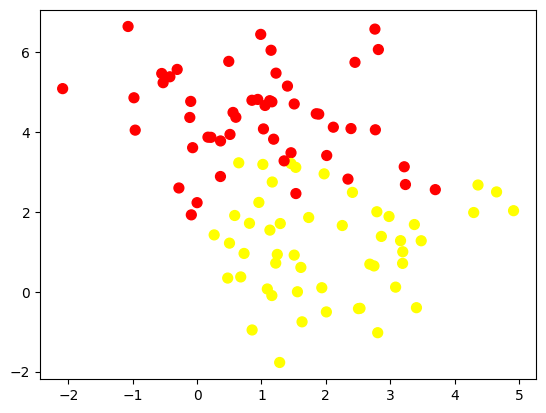

In [3]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

Dengan `cluster_std=1.2`, sebaran kedua kelas menjadi lebih lebar dibanding praktikum 1 sehingga ujung-ujung kelompok saling bertemu di bagian tengah. Garis lurus apa pun yang dipakai akan menyisakan beberapa titik di sisi yang salah, jadi hard margin tidak lagi layak dipakai di sini. Karena itu margin perlu dilonggarkan dengan mengatur parameter `C`.

## Langkah 3 - Analisis Dampak Tuning

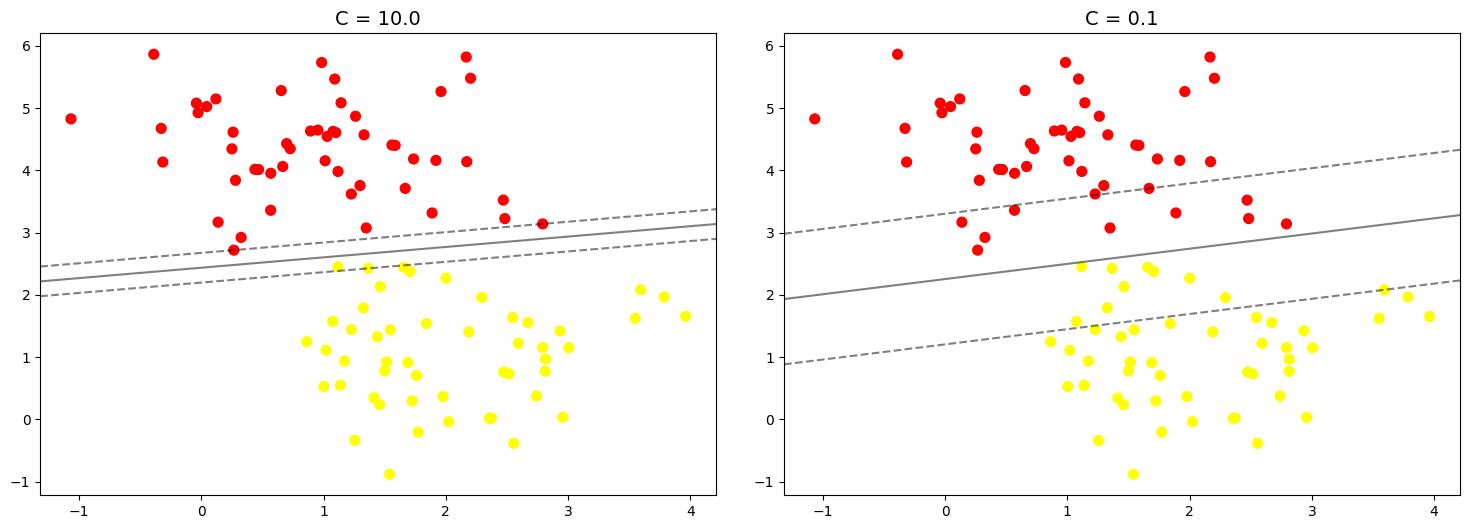

In [4]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)
plt.show()

In [5]:
for C in [10.0, 0.1]:
    m = SVC(kernel='linear', C=C).fit(X, y)
    print(f'C = {C:>5} -> jumlah support vector = {len(m.support_vectors_):>3}, akurasi training = {m.score(X, y):.2f}')

C =  10.0 -> jumlah support vector =   4, akurasi training = 1.00
C =   0.1 -> jumlah support vector =  20, akurasi training = 1.00


Pada contoh ini yang berubah adalah lebar margin dan jumlah support vector. Dengan `C = 10`, margin sempit dan hanya ada `4` support vector, karena model dipaksa menjaga hampir semua titik berada di luar margin. Dengan `C = 0.1`, margin jauh lebih lebar dan jumlah support vector naik menjadi `20`, karena banyak titik yang kini boleh berada di dalam margin tanpa dihukum berat. Akurasi training pada keduanya sama-sama `1.00`, sehingga perbedaannya tidak terlihat dari skor, melainkan dari bentuk margin: `C` besar membuat model mengikuti titik-titik dekat batas, sedangkan `C` kecil lebih mengutamakan margin yang lebar dan stabil.

Jobsheet menyebutkan bahwa nilai `C` yang optimal bergantung pada dataset dan dicari lewat cross-validation. Sebagai pelengkap, berikut cross-validation 5-fold untuk beberapa nilai `C` pada data yang sama.

In [6]:
from sklearn.model_selection import cross_val_score
import pandas as pd

hasil = []
for C in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    skor = cross_val_score(SVC(kernel='linear', C=C), X, y, cv=5)
    hasil.append({'C': C, 'rata-rata akurasi CV': skor.mean(), 'simpangan baku': skor.std()})

pd.DataFrame(hasil)

,C,rata-rata akurasi CV,simpangan baku
0,0.001,0.99,0.020000
1,0.010,0.99,0.020000
2,0.100,1.00,0.000000
3,1.000,0.98,0.024495
4,10.000,0.99,0.020000
5,100.000,0.99,0.020000
6,1000.000,0.99,0.020000


Hasil cross-validation 5-fold menunjukkan bahwa `C = 0.1` memberi rata-rata akurasi tertinggi (`1.00` dengan simpangan baku `0`), sedangkan `C = 1` menjadi yang terendah (`0.98`). Perbedaan antar nilai `C` sebenarnya sangat kecil, hanya sekitar satu sampel dari 100, karena data pada percobaan ini hampir terpisah sempurna. Jadi pada dataset ini akurasi tidak terlalu sensitif terhadap `C`, tetapi `C = 0.1` tetap layak dipilih karena paling stabil antar lipatan. Pada data yang tumpang tindih lebih parah, pengaruh `C` terhadap akurasi biasanya jauh lebih terlihat, dan di situlah cross-validation benar-benar berguna untuk memilih nilai yang tepat.